# Статистический анализ и прогноз исхода футбольного матча

## Цель

Статистически определить 2–3 предматчевые характеристики, которые связаны
с исходом матча (`H`/`D`/`A` — победа хозяев / ничья / победа гостей), и
проверить их на простой интерпретируемой модели, которая выдаёт
вероятности всех трёх исходов.

Подготовка признаков (feature engineering, anti-leakage проверки) выполнена
отдельно — в `1_football_data_preparation.ipynb`.
Этот notebook начинается с уже подготовленного match-level датасета (`matches_with_form_squad_teamattrs.csv`) и не
повторяет эту работу.

## Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
PROJECT_ROOT = Path.cwd()
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
INPUT_CSV = INTERIM_DIR / "matches_with_form_squad_teamattrs.csv"

# 1. Данные для анализа

**Что проверяем.** Из подготовленного файла
`csv/matches_with_form_squad_teamattrs.csv` формируется выборка
матчей, на которой строится весь дальнейший анализ.

**Зачем.** Не все сезоны одинаково пригодны для анализа: более старые
данные хуже покрыты характеристиками состава, а для прогноза важна
актуальность.

**Что получилось.** Analytical sample — сезоны **2010/2011–2015/2016**, без
**Belgium Jupiler League 2013/2014** (в датасете это неполный фрагмент
сезона — 12 матчей вместо ~240). 
Причины:
структурный провал coverage `team_attributes` до 2010 года и приоритет
более свежих сезонов для прогноза из точки 2017 года. Исходные файлы физически
не обрезаются — старые сезоны остаются доступны как база для
form-признаков (расчёт "последних 5 матчей" может заглядывать за пределы
analytical sample).

In [3]:
matches = pd.read_csv(INPUT_CSV)
matches["date"] = pd.to_datetime(matches["date"])

season_start_year = matches["season"].str.slice(0, 4).astype(int)
is_belgium_2013_2014 = (
    (matches["league"] == "Belgium Jupiler League") & (matches["season"] == "2013/2014")
)
analysis_matches = matches[(season_start_year >= 2010) & (~is_belgium_2013_2014)].copy()

assert len(analysis_matches) == 19411, "Ожидали 19 411 матчей в analytical sample"

data_summary = pd.DataFrame({
    "metric": ["матчей в analytical sample", "период (сезоны)", "лиг", "классов исхода (target)"],
    "value": [
        len(analysis_matches),
        f"{analysis_matches['season'].min()}–{analysis_matches['season'].max()}",
        analysis_matches["league"].nunique(),
        ", ".join(sorted(analysis_matches["result"].unique())),
    ],
}).set_index("metric")
data_summary

,value
metric,
матчей в analytical sample,19411
период (сезоны),2010/2011–2015/2016
лиг,11
классов исхода (target),"A, D, H"


# 2. Целевая переменная

**Что проверяем.** Распределение классов исхода матча.

**Зачем.** Оно определяет, нужен ли содержательный baseline: если один
исход резко преобладает, простое "всегда предсказывать самый частый исход"
уже даёт немалую точность, и модель должна её превзойти.

`H` — победа хозяев, `D` — ничья, `A` — победа гостей.

In [4]:
target_distribution = (analysis_matches["result"].value_counts(normalize=True) * 100).round(1)
target_distribution = target_distribution.reindex(["H", "D", "A"]).rename("share_%").to_frame()
target_distribution

,share_%
result,
H,45.4
D,25.5
A,29.1


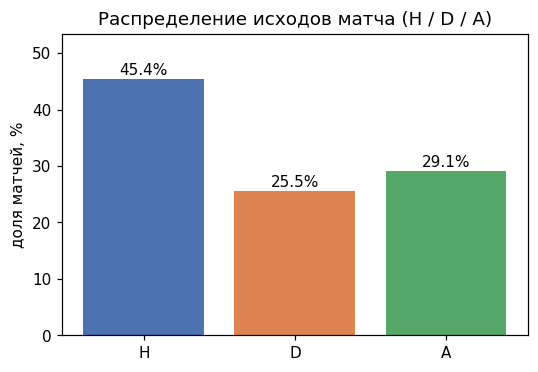

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
colors = ["#4C72B0", "#DD8452", "#55A868"]
ax.bar(target_distribution.index, target_distribution["share_%"], color=colors)
for x, y in zip(target_distribution.index, target_distribution["share_%"]):
    ax.text(x, y + 0.8, f"{y:.1f}%", ha="center", fontsize=10)
ax.set_ylabel("доля матчей, %")
ax.set_title("Распределение исходов матча (H / D / A)")
ax.set_ylim(0, target_distribution["share_%"].max() + 8)
plt.tight_layout()
plt.show()

**Вывод.** Домашняя победа — самый частый исход (~45%), заметно опережает
ничью (~26%) и выездную победу (~29%). Поэтому в дальнейшем сравнении
обязателен содержательный baseline (раздел 9), а не абсолютное значение
accuracy само по себе.

# 3. Какие характеристики проверялись

**Что проверяем.** Три смысловые группы предматчевых характеристик,
каждая уже посчитана как `home_value − away_value` (`diff`). Положительное
значение `diff` = преимущество хозяев по этой характеристике.

**Зачем.** Задача — сравнение двух команд перед конкретным матчем, поэтому
везде используется именно разница домашней и гостевой команды, а не
абсолютные значения.

In [6]:
CANDIDATE_FEATURES = [
    ("points_last_5_diff", "form"),
    ("win_rate_last_5_diff", "form"),
    ("avg_goals_scored_last_5_diff", "form"),
    ("avg_goals_conceded_last_5_diff", "form"),
    ("avg_goal_difference_last_5_diff", "form"),
    ("overall_rating_diff", "squad"),
    ("buildUpPlaySpeed_diff", "team_style"),
    ("buildUpPlayPassing_diff", "team_style"),
    ("chanceCreationPassing_diff", "team_style"),
    ("chanceCreationShooting_diff", "team_style"),
    ("defencePressure_diff", "team_style"),
    ("defenceAggression_diff", "team_style"),
]

GROUP_MEANING = {
    "form": "форма команды за последние 5 матчей (очки, доля побед, забитые/пропущенные голы, разница голов)",
    "squad": "сила стартового состава (разница среднего FIFA overall rating)",
    "team_style": "стиль игры команды (6 FIFA team-attributes: атака, пас, давление, агрессия обороны)",
}

candidates_df = pd.DataFrame(CANDIDATE_FEATURES, columns=["feature", "feature_group"])
feature_summary = (
    candidates_df.groupby("feature_group")["feature"]
    .apply(lambda s: ", ".join(s))
    .rename("candidates")
    .to_frame()
)
feature_summary["meaning"] = feature_summary.index.map(GROUP_MEANING)
feature_summary

,candidates,meaning
feature_group,,
form,"points_last_5_diff, win_rate_last_5_diff, avg_goals_scored_last_5_diff, avg_goals_conceded_last_5_diff, avg_goal_difference_last_5_diff","форма команды за последние 5 матчей (очки, доля побед, забитые/пропущенные голы, разница голов)"
squad,overall_rating_diff,сила стартового состава (разница среднего FIFA overall rating)
team_style,"buildUpPlaySpeed_diff, buildUpPlayPassing_diff, chanceCreationPassing_diff, chanceCreationShooting_diff, defencePressure_diff, defenceAggression_diff","стиль игры команды (6 FIFA team-attributes: атака, пас, давление, агрессия обороны)"


Признаки сравниваются внутри `league` — команды одного матча (почти)
всегда одной лиги; `league` используется как контекстная переменная, а не
кандидат сам по себе.

# 4. Метод статистической проверки

**Что проверяем.** Для каждого кандидата сравниваем распределение признака
между исходами `H`/`D`/`A` — тестом **Kruskal–Wallis** (непараметрический
аналог ANOVA, не требует нормальности распределения).

**Зачем.** При выборке в 18–19 тыс. матчей даже крошечное различие даёт
p-value около нуля — сам p-value не говорит о практической значимости.
Поэтому основной критерий отбора — **effect size** (epsilon-squared,
стандартная нормировка H-статистики: `ε² = H·(n+1)/(n²−1)`), а p-value —
вспомогательный. Дополнительно устойчивость результата проверяется отдельно
внутри каждой из 11 лиг (не выводим все 11×12 = 132 теста построчно —
только агрегированную сводку: сколько лиг подтверждают эффект).

Для `overall_rating_diff` статистика считается на подвыборке
`squad_rating_reliable == True` (не менее 10 из 11 игроков стартового
состава известны с каждой стороны — критерий зафиксирован в
`notes/decisions.md`).

In [7]:
def kruskal_wallis_with_effect_size(df, feature, group_col="result", groups=("H", "D", "A")):
    samples = [df.loc[df[group_col] == g, feature].dropna() for g in groups]
    n = sum(len(s) for s in samples)
    if n == 0 or any(len(s) < 5 for s in samples):
        return {"n": n, "statistic": np.nan, "p_value": np.nan, "effect_size": np.nan}
    statistic, p_value = kruskal(*samples)
    epsilon_squared = statistic * (n + 1) / (n**2 - 1)
    return {"n": n, "statistic": statistic, "p_value": p_value, "effect_size": epsilon_squared}


squad_sample = analysis_matches[analysis_matches["squad_rating_reliable"]].copy()
print("Coverage overall_rating_diff (squad_rating_reliable):",
      f"{len(squad_sample) / len(analysis_matches):.2%}")

Coverage overall_rating_diff (squad_rating_reliable): 95.88%

# 5. Результаты статистического анализа

**Что проверяем.** Effect size каждого кандидата (global) и его
устойчивость по лигам (сколько из 11 лиг подтверждают эффект и ожидаемое
направление).

**Зачем.** Это главный статистический аргумент для отбора shortlist в
разделе 7.

In [8]:
FEATURE_DIRECTION = {
    "points_last_5_diff": 1, "win_rate_last_5_diff": 1,
    "avg_goals_scored_last_5_diff": 1, "avg_goals_conceded_last_5_diff": -1,
    "avg_goal_difference_last_5_diff": 1, "overall_rating_diff": 1,
    "buildUpPlaySpeed_diff": None, "buildUpPlayPassing_diff": None,
    "chanceCreationPassing_diff": None, "chanceCreationShooting_diff": None,
    "defencePressure_diff": None, "defenceAggression_diff": None,
}

global_rows, league_rows = [], []
for feature, group in CANDIDATE_FEATURES:
    source_df = squad_sample if feature == "overall_rating_diff" else analysis_matches
    global_rows.append({"feature": feature, "feature_group": group,
                         **kruskal_wallis_with_effect_size(source_df, feature)})
    for league_name, league_df in source_df.groupby("league"):
        sizes = league_df.groupby("result")[feature].apply(lambda s: s.notna().sum())
        if sizes.shape[0] < 3 or (sizes < 5).any():
            continue
        result = kruskal_wallis_with_effect_size(league_df, feature)
        medians = league_df.groupby("result")[feature].median()
        league_rows.append({"feature": feature, "league": league_name, "p_value": result["p_value"],
                             "median_H": medians.get("H", np.nan), "median_A": medians.get("A", np.nan)})

global_results = pd.DataFrame(global_rows)
league_results = pd.DataFrame(league_rows)


def league_consistency(feature):
    direction = FEATURE_DIRECTION[feature]
    subset = league_results[league_results["feature"] == feature]
    n_leagues = len(subset)
    n_sig = int((subset["p_value"] < 0.05).sum())
    if direction == 1:
        n_expected_dir = int((subset["median_H"] > subset["median_A"]).sum())
    elif direction == -1:
        n_expected_dir = int((subset["median_H"] < subset["median_A"]).sum())
    else:
        n_expected_dir = None
    return n_leagues, n_sig, n_expected_dir


rows = []
for feature, group in CANDIDATE_FEATURES:
    eff = global_results.loc[global_results["feature"] == feature, "effect_size"].iloc[0]
    n_leagues, n_sig, n_expected_dir = league_consistency(feature)
    rows.append({
        "feature": feature,
        "feature_group": group,
        "effect_size": round(eff, 4),
        "league_consistency": f"{n_expected_dir}/{n_leagues} ожид. направление" if n_expected_dir is not None
                                else f"{n_sig}/{n_leagues} p<0.05",
    })

summary_table = pd.DataFrame(rows).sort_values("effect_size", ascending=False).reset_index(drop=True)
summary_table["interpretation"] = np.select(
    [summary_table["effect_size"] >= 0.1, summary_table["effect_size"] >= 0.02],
    ["сильный эффект", "слабый/умеренный эффект"],
    default="эффект практически отсутствует",
)
summary_table["status"] = np.where(
    summary_table["feature"].isin(["overall_rating_diff", "avg_goal_difference_last_5_diff",
                                    "points_last_5_diff", "avg_goals_conceded_last_5_diff"]),
    "в shortlist", "исключён",
)
summary_table

,feature,feature_group,effect_size,league_consistency,interpretation,status
0,overall_rating_diff,squad,0.1291,11/11 ожид. направление,сильный эффект,в shortlist
1,avg_goal_difference_last_5_diff,form,0.0590,11/11 ожид. направление,слабый/умеренный эффект,в shortlist
2,points_last_5_diff,form,0.0488,11/11 ожид. направление,слабый/умеренный эффект,в shortlist
3,avg_goals_scored_last_5_diff,form,0.0446,11/11 ожид. направление,слабый/умеренный эффект,исключён
4,win_rate_last_5_diff,form,0.0430,8/11 ожид. направление,слабый/умеренный эффект,исключён
5,avg_goals_conceded_last_5_diff,form,0.0261,11/11 ожид. направление,слабый/умеренный эффект,в shortlist
6,defencePressure_diff,team_style,0.0133,7/11 p<0.05,эффект практически отсутствует,исключён
7,buildUpPlayPassing_diff,team_style,0.0064,8/11 p<0.05,эффект практически отсутствует,исключён
8,defenceAggression_diff,team_style,0.0048,8/11 p<0.05,эффект практически отсутствует,исключён
9,chanceCreationShooting_diff,team_style,0.0026,5/11 p<0.05,эффект практически отсутствует,исключён


**Сила состава.** `overall_rating_diff` — самый сильный кандидат
(ε² ≈ 0.129), ожидаемое направление подтверждается в 11 из 11 лиг.

**Форма.** Лучший form-признак — `avg_goal_difference_last_5_diff`
(ε² ≈ 0.059), тоже 11/11 лиг. Остальные form-признаки слабее и частично
дублируют информацию друг друга (раздел 6) — особенно `points_last_5_diff`
и `win_rate_last_5_diff`.

**Стиль игры.** Effect size у всех 6 признаков стиля игры очень маленький
(максимум ≈ 0.013), поэтому вся эта группа не проходит в shortlist.

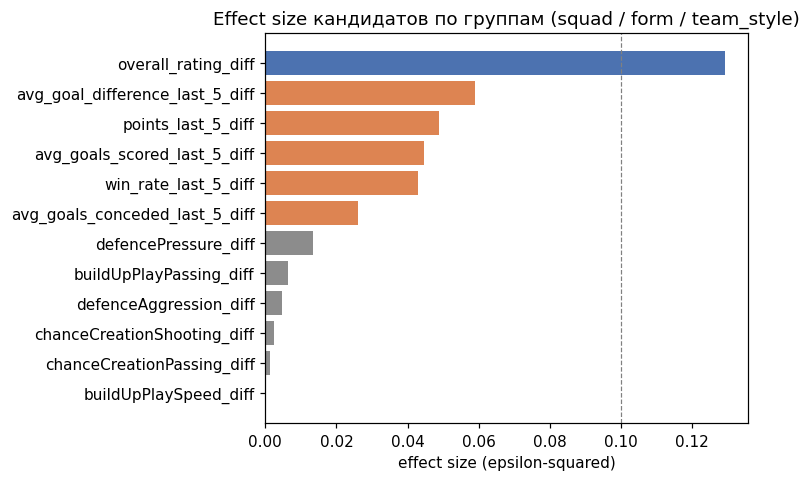

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_data = summary_table.sort_values("effect_size")
bar_colors = plot_data["feature_group"].map({"squad": "#4C72B0", "form": "#DD8452", "team_style": "#8C8C8C"})
ax.barh(plot_data["feature"], plot_data["effect_size"], color=bar_colors)
ax.axvline(0.1, color="grey", linewidth=0.8, linestyle="--")
ax.set_xlabel("effect size (epsilon-squared)")
ax.set_title("Effect size кандидатов по группам (squad / form / team_style)")
plt.tight_layout()
plt.show()

# 6. Корреляция form-признаков

**Что проверяем.** Корреляцию (Spearman) между пятью form-признаками.

**Зачем.** Проверить, не дублируют ли они друг друга — если да, нет смысла
включать в модель несколько сильно скоррелированных признаков сразу.

In [10]:
form_features = [f for f, g in CANDIDATE_FEATURES if g == "form"]
form_correlation = analysis_matches[form_features].corr(method="spearman")
form_correlation.round(2)

,points_last_5_diff,win_rate_last_5_diff,avg_goals_scored_last_5_diff,avg_goals_conceded_last_5_diff,avg_goal_difference_last_5_diff
points_last_5_diff,1.00,0.95,0.71,-0.63,0.88
win_rate_last_5_diff,0.95,1.00,0.69,-0.54,0.81
avg_goals_scored_last_5_diff,0.71,0.69,1.00,-0.20,0.77
avg_goals_conceded_last_5_diff,-0.63,-0.54,-0.20,1.00,-0.74
avg_goal_difference_last_5_diff,0.88,0.81,0.77,-0.74,1.00


**Вывод.** `points_last_5_diff` и `win_rate_last_5_diff` коррелируют очень
сильно (r ≈ 0.95 — почти дубликат), `points_last_5_diff` также заметно
коррелирует с `avg_goal_difference_last_5_diff` (r ≈ 0.88). Несколько
form-признаков описывают почти одну и ту же информацию — включать их все в
финальную модель нет смысла.

# 7. Shortlist

По effect size, устойчивости по лигам и coverage до проверки на модели
дошли 4 признака (остальные form-признаки — как дублирующие уже включённые,
весь блок `team_style` — как статистически заметно более слабый):

| feature | группа | effect size | лиги (ожид. направление) | coverage |
|---|---|---|---|---|
| `overall_rating_diff` | squad | 0.129 | 11/11 | 95.88% |
| `avg_goal_difference_last_5_diff` | form | 0.059 | 11/11 | 99.56% |
| `points_last_5_diff` | form | 0.049 | 11/11 | 99.56% |
| `avg_goals_conceded_last_5_diff` | form | 0.026 | 11/11 | 99.56% |

Shortlist шире финального выбора: он должен пройти ещё и проверку в
совместной модели (разделы 10–11) — статистически значимый по отдельности
признак может не добавлять самостоятельной пользы рядом с более сильными.
Эти 4 признака + `league` как категориальный контекст идут в модель ниже.

In [11]:
SHORTLIST_FEATURES = [
    "overall_rating_diff",
    "avg_goal_difference_last_5_diff",
    "points_last_5_diff",
    "avg_goals_conceded_last_5_diff",
]
SHORTLIST_FEATURES

['overall_rating_diff', 'avg_goal_difference_last_5_diff', 'points_last_5_diff', 'avg_goals_conceded_last_5_diff']

# 8. Temporal validation

**Что проверяем.** Разбиение на train/validation/test.

**Зачем.** Модель прогнозирует будущее по прошлым данным, поэтому split
строго по сезонам, не случайный: random split позволил бы модели видеть
матчи того же сезона в train, что не соответствует реальному сценарию
использования (прогноз ещё не сыгранных матчей).

- **TRAIN**: 2010/2011–2013/2014
- **VALIDATION**: 2014/2015
- **TEST**: 2015/2016 (используется один раз, в самом конце)

In [12]:
TRAIN_SEASONS = ["2010/2011", "2011/2012", "2012/2013", "2013/2014"]
VAL_SEASONS = ["2014/2015"]
TEST_SEASONS = ["2015/2016"]

analysis_matches["split"] = np.select(
    [analysis_matches["season"].isin(TRAIN_SEASONS),
     analysis_matches["season"].isin(VAL_SEASONS),
     analysis_matches["season"].isin(TEST_SEASONS)],
    ["train", "validation", "test"],
    default="unknown",
)

train_matches = analysis_matches[analysis_matches["split"] == "train"]
val_matches = analysis_matches[analysis_matches["split"] == "validation"]
test_matches = analysis_matches[analysis_matches["split"] == "test"]

split_summary = pd.DataFrame({
    "n": [len(train_matches), len(val_matches), len(test_matches)],
    "H_%": [train_matches["result"].eq("H").mean() * 100, val_matches["result"].eq("H").mean() * 100, test_matches["result"].eq("H").mean() * 100],
    "D_%": [train_matches["result"].eq("D").mean() * 100, val_matches["result"].eq("D").mean() * 100, test_matches["result"].eq("D").mean() * 100],
    "A_%": [train_matches["result"].eq("A").mean() * 100, val_matches["result"].eq("A").mean() * 100, test_matches["result"].eq("A").mean() * 100],
}, index=["train", "validation", "test"]).round(1)
split_summary

,n,H_%,D_%,A_%
train,12760,45.9,25.4,28.7
validation,3325,44.9,25.6,29.5
test,3326,43.9,25.7,30.4


**Вывод.** 12 760 / 3 325 / 3 326 матчей, распределение `H`/`D`/`A`
стабильно между сплитами — сравнение метрик между ними корректно.

# 9. Baseline

**Что проверяем.** Историческая вероятность `H`/`D`/`A` отдельно по
`league`, посчитанная только на train и применённая без пересчёта к
validation/test.

**Зачем.** Модель имеет ценность только если она стабильно превосходит
этот простой исторический baseline — иначе её сложность не оправдана.

In [13]:
TARGET = "result"
RESULT_CLASSES = ["A", "D", "H"]

league_baseline_probs = (
    train_matches.groupby("league")["result"].value_counts(normalize=True)
    .unstack().reindex(columns=RESULT_CLASSES)
)
global_baseline_probs = train_matches["result"].value_counts(normalize=True).reindex(RESULT_CLASSES)


def baseline_predict_proba(df):
    rows = [league_baseline_probs.loc[lg] if lg in league_baseline_probs.index else global_baseline_probs
            for lg in df["league"]]
    return np.vstack(rows)


def evaluate_baseline(df):
    proba = baseline_predict_proba(df)
    pred = np.array(RESULT_CLASSES)[proba.argmax(axis=1)]
    return accuracy_score(df["result"], pred), log_loss(df["result"], proba, labels=RESULT_CLASSES)


baseline_rows = []
for label, df in [("validation", val_matches), ("test", test_matches)]:
    acc, ll = evaluate_baseline(df)
    baseline_rows.append({"split": label, "accuracy": round(acc, 4), "log_loss": round(ll, 4)})

baseline_metrics = pd.DataFrame(baseline_rows).set_index("split")
baseline_metrics

,accuracy,log_loss
split,,
validation,0.4493,1.0704
test,0.4387,1.0725


**Вывод.** Baseline даёт accuracy ≈ 0.45 на validation и ≈ 0.44 на test —
модель должна быть лучше этого уровня, иначе она не даёт ценности по
сравнению с простым историческим правилом.

# 10. Первоначальная 4-feature модель

**Что проверяем.** Logistic regression (multinomial) на всём shortlist из
4 признаков + `league` — предварительный шаг перед финальным выбором.

**Зачем.** Проверить вклад каждого признака внутри совместной модели —
статистическая значимость по отдельности (раздел 5) не гарантирует
самостоятельную предсказательную пользу рядом с более сильными признаками.

Preprocessing: числовые признаки — `SimpleImputer(strategy="median")` →
`StandardScaler`; `league` — `OneHotEncoder(handle_unknown="ignore")`. Все
шаги обучаются (`fit`) только на train.

In [14]:
EXPLORATORY_MODEL_FEATURES = SHORTLIST_FEATURES + ["league"]

preprocessor_4f = ColumnTransformer(transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), SHORTLIST_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["league"]),
])
model_4f = Pipeline([("preprocess", preprocessor_4f), ("logreg", LogisticRegression(max_iter=1000))])
model_4f.fit(train_matches[EXPLORATORY_MODEL_FEATURES], train_matches[TARGET])


def evaluate_model(estimator, df, features):
    X = df[features]
    pred = estimator.predict(X)
    proba = estimator.predict_proba(X)
    return accuracy_score(df["result"], pred), log_loss(df["result"], proba, labels=estimator.named_steps["logreg"].classes_)


rows = []
for label, df in [("validation", val_matches), ("test", test_matches)]:
    base_acc, base_ll = evaluate_baseline(df)
    model_acc, model_ll = evaluate_model(model_4f, df, EXPLORATORY_MODEL_FEATURES)
    rows.append({"split": label, "method": "baseline", "accuracy": round(base_acc, 4), "log_loss": round(base_ll, 4)})
    rows.append({"split": label, "method": "4-feature logistic regression", "accuracy": round(model_acc, 4), "log_loss": round(model_ll, 4)})

comparison_4f = pd.DataFrame(rows).pivot(index="method", columns="split", values=["accuracy", "log_loss"])
comparison_4f

accuracy            log_loss           
split                             test validation     test validation
method                                                               
4-feature logistic regression   0.5024     0.5191   1.0007     0.9888
baseline                        0.4387     0.4493   1.0725     1.0704

In [15]:
coefficients_4f = pd.DataFrame(
    model_4f.named_steps["logreg"].coef_[:, :len(SHORTLIST_FEATURES)],
    index=model_4f.named_steps["logreg"].classes_,
    columns=SHORTLIST_FEATURES,
).round(3)
coefficients_4f

,overall_rating_diff,avg_goal_difference_last_5_diff,points_last_5_diff,avg_goals_conceded_last_5_diff
A,-0.439,-0.097,0.021,-0.002
D,-0.001,-0.023,-0.004,0.003
H,0.440,0.120,-0.016,-0.001


**Вывод.** Модель на 4 признаках стабильно лучше baseline на обоих
сплитах. Коэффициенты (признаки стандартизированы, поэтому сравнимы по
относительной силе): `overall_rating_diff` — на порядок сильнее остальных,
`avg_goal_difference_last_5_diff` — второй по силе с ожидаемым знаком.
`points_last_5_diff` и `avg_goals_conceded_last_5_diff` получили
коэффициенты, близкие к нулю — в присутствии первых двух признаков они
почти не добавляют самостоятельной информации. Это ожидаемо:
`points_last_5_diff` сильно коррелирует с `avg_goal_difference_last_5_diff`
(раздел 6, r ≈ 0.88) — в совместной модели один признак "забирает" вклад
похожего на него другого.

# 11. Финальная модель

Объединяя статистику (раздел 5 — effect size, устойчивость по лигам) и
модель (раздел 10 — коэффициенты), финальные характеристики:

1. **Сила стартового состава** (`overall_rating_diff`) — самая сильная
   предматчевая характеристика: лидирует и по effect size (ε² ≈ 0.129), и
   по коэффициенту модели.
2. **Форма команды по разнице голов последних 5 матчей**
   (`avg_goal_difference_last_5_diff`) — вторая по силе связи с исходом,
   лучший из form-признаков и по effect size, и по вкладу в модель.

Два признака, не четыре: `points_last_5_diff` и
`avg_goals_conceded_last_5_diff` статистически значимы по отдельности, но в
совместной модели не подтвердили самостоятельную предсказательную пользу
сверх уже выбранных двух. Это **упрощение модели после обнаружения
избыточных предикторов**, а не отдельная попытка улучшить accuracy.

Финальная модель — multinomial logistic regression на:
`overall_rating_diff`, `avg_goal_difference_last_5_diff`, `league`.

In [16]:
FINAL_MODEL_FEATURES = ["overall_rating_diff", "avg_goal_difference_last_5_diff"]
MODEL_FEATURES = FINAL_MODEL_FEATURES + ["league"]

preprocessor_final = ColumnTransformer(transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), FINAL_MODEL_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["league"]),
])
model = Pipeline([("preprocess", preprocessor_final), ("logreg", LogisticRegression(max_iter=1000))])
model.fit(train_matches[MODEL_FEATURES], train_matches[TARGET])
print("Классы финальной модели:", list(model.named_steps["logreg"].classes_))

Классы финальной модели: ['A', 'D', 'H']

In [17]:
rows = []
for label, df in [("validation", val_matches), ("test", test_matches)]:
    acc_4f, ll_4f = evaluate_model(model_4f, df, EXPLORATORY_MODEL_FEATURES)
    acc_2f, ll_2f = evaluate_model(model, df, MODEL_FEATURES)
    rows.append({"split": label, "method": "4-feature (промежуточный шаг)", "accuracy": round(acc_4f, 4), "log_loss": round(ll_4f, 4)})
    rows.append({"split": label, "method": "final 2-feature", "accuracy": round(acc_2f, 4), "log_loss": round(ll_2f, 4)})

model_comparison = pd.DataFrame(rows).pivot(index="method", columns="split", values=["accuracy", "log_loss"])
model_comparison

accuracy            log_loss           
split                             test validation     test validation
method                                                               
4-feature (промежуточный шаг)   0.5024     0.5191   1.0007     0.9888
final 2-feature                 0.5027     0.5167   1.0007     0.9888

**Вывод.** Точность и log loss финальной 2-признаковой модели практически
не отличаются от 4-признаковой версии на обоих сплитах — исключение
`points_last_5_diff` и `avg_goals_conceded_last_5_diff` не ухудшило модель.
Более простая 2-признаковая модель предпочтительнее.

# 12. Финальные метрики модели

Baseline vs финальная модель на обоих сплитах:

In [18]:
final_rows = []
for label, df in [("validation", val_matches), ("test", test_matches)]:
    base_acc, base_ll = evaluate_baseline(df)
    model_acc, model_ll = evaluate_model(model, df, MODEL_FEATURES)
    final_rows.append({"split": label, "method": "baseline", "accuracy": round(base_acc, 4), "log_loss": round(base_ll, 4)})
    final_rows.append({"split": label, "method": "final 2-feature model", "accuracy": round(model_acc, 4), "log_loss": round(model_ll, 4)})

baseline_vs_final = pd.DataFrame(final_rows).pivot(index="method", columns="split", values=["accuracy", "log_loss"])
baseline_vs_final

accuracy            log_loss           
split                     test validation     test validation
method                                                       
baseline                0.4387     0.4493   1.0725     1.0704
final 2-feature model   0.5027     0.5167   1.0007     0.9888

In [19]:
test_confusion = confusion_matrix(test_matches["result"], model.predict(test_matches[MODEL_FEATURES]), labels=["H", "D", "A"])
confusion_df = pd.DataFrame(test_confusion, index=["actual_H", "actual_D", "actual_A"], columns=["pred_H", "pred_D", "pred_A"])
confusion_df

,pred_H,pred_D,pred_A
actual_H,1239,1,219
actual_D,634,0,221
actual_A,577,2,433


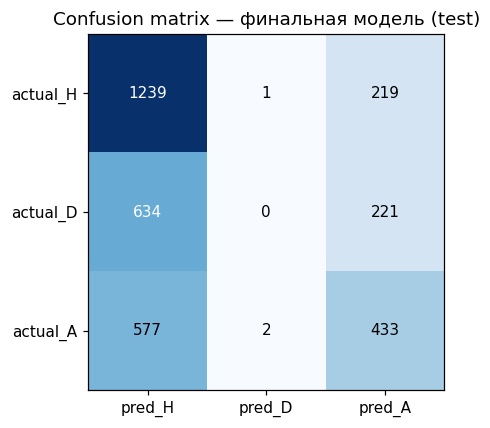

In [20]:
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(test_confusion, cmap="Blues")
labels = ["H", "D", "A"]
ax.set_xticks(range(3)); ax.set_xticklabels([f"pred_{l}" for l in labels])
ax.set_yticks(range(3)); ax.set_yticklabels([f"actual_{l}" for l in labels])
for i in range(3):
    for j in range(3):
        ax.text(j, i, test_confusion[i, j], ha="center", va="center",
                 color="white" if test_confusion[i, j] > test_confusion.max() / 2 else "black")
ax.set_title("Confusion matrix — финальная модель (test)")
plt.tight_layout()
plt.show()

**Вывод.** Финальная модель стабильно превосходит baseline по accuracy и
log loss на обоих сплитах, небольшое и ожидаемое ухудшение от validation к
test — признаков переобучения нет. Confusion matrix показывает известное
ограничение: модель почти никогда не предсказывает `D` (ничью) —
предсказания сосредоточены между `H` и `A`. Ничьи статистически не
выглядят как отдельный, легко отделимый кластер; специальных мер (class
weighting и т.п.) сознательно не вводили — вне объёма учебного MVP.

# 13. Интерпретация финальных характеристик

### 1. Сила стартового состава — `overall_rating_diff`

Главный predictor. Положительное значение означает, что средний FIFA
overall rating стартового состава хозяев выше, чем у гостей. Связь с
исходом — самая сильная среди всех рассмотренных характеристик.

### 2. Текущая форма — `avg_goal_difference_last_5_diff`

Разница в средней разнице голов за предыдущие 5 матчей. Положительное
значение — форма хозяев лучше. Второй по силе независимый predictor.

Обе характеристики **связаны** с исходом и имеют **предсказательную
ценность** — это не означает, что они *вызывают* победу (причинно-следственную
связь эти данные не устанавливают).

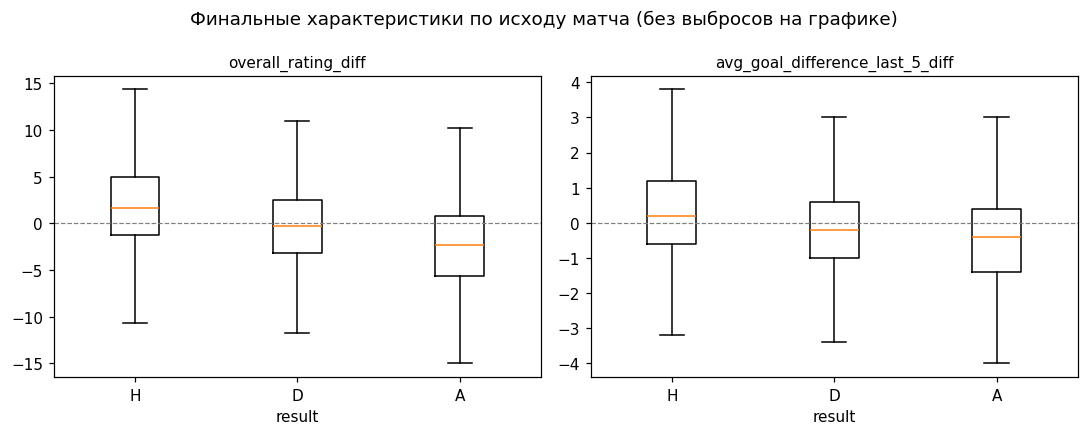

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, feature in zip(axes, FINAL_MODEL_FEATURES):
    source_df = squad_sample if feature == "overall_rating_diff" else analysis_matches
    data_by_group = [source_df.loc[source_df["result"] == g, feature].dropna() for g in ["H", "D", "A"]]
    ax.boxplot(data_by_group, tick_labels=["H", "D", "A"], showfliers=False)
    ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("result")

fig.suptitle("Финальные характеристики по исходу матча (без выбросов на графике)")
plt.tight_layout()
plt.show()

Медианы обеих характеристик выше при `H`, ниже при `A`, `D` — посередине,
что согласуется со статистическими результатами раздела 5.

# 14. Ограничения

- Accuracy на test ≈ 50% — заметно лучше baseline, но далеко не идеальный
  прогноз; футбол по природе высоко непредсказуем.
- Задача трёхклассовая, и модель почти не предсказывает ничьи (`D`) —
  исходы `H`/`A` разделяются заметно лучше, чем `D` от соседних классов.
- При выборе одного наиболее вероятного исхода модель редко присваивает первое место классу D. При этом вероятность ничьей рассчитывается для каждого матча и сохраняется в вероятностном прогнозе H/D/A.
- Сложные методы (calibration, class weighting, ансамбли, подбор
  гиперпараметров, букмекерский benchmark) сознательно не применялись — это
  учебный интерпретируемый проект, цель которого — простой понятный
  прогноз, а не максимальная accuracy любой ценой.

# 15. Финальный вывод

На **19 411 матчах** (сезоны 2010/2011–2015/2016, без Belgium Jupiler
League 2013/2014) статистически проверены предматчевые характеристики
формы, силы состава и стиля игры. Финально выбраны:

1. **сила стартового состава** (`overall_rating_diff`);
2. **текущая форма по разнице голов последних 5 матчей**
   (`avg_goal_difference_last_5_diff`).

Обе характеристики статистически устойчивы (effect size, согласованность
по 11 лигам), интерпретируемы и сохраняют предсказательную ценность в
temporal validation (обучение на прошлом, проверка на будущих сезонах).

Финальная **multinomial logistic regression** (`overall_rating_diff` +
`avg_goal_difference_last_5_diff` + `league`) превосходит исторический
baseline по accuracy и log loss на validation и test:

| | baseline (val / test) | финальная модель (val / test) |
|---|---|---|
| accuracy | 0.4493 / 0.4387 | 0.5167 / 0.5027 |
| log loss | 1.0704 / 1.0725 | 0.9888 / 1.0007 |

Модель используется для расчёта вероятностей всех трёх исходов —
`probability_home` / `probability_draw` / `probability_away`.